# 02 · Training the candidate models

Feature extraction, the leakage-aware cross-validation protocol and every candidate model, run from the same
package code as `scripts/run_experiments.py`. Cheap models are trained live here; the full 30-run CNN fine-tuning sweep
(~10 min on 4 CPU cores) is loaded from `artifacts/metrics` and one fold is re-trained live to show the loop.

In [1]:
import sys, os, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "default.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("GLOG_minloglevel", "2")
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from salat_vision.config import get_config
from salat_vision.viz import apply_style
apply_style()
cfg = get_config()
print("project root:", ROOT)

project root: /home/user/Shalat-Postures-Detection


In [2]:
import platform, torch, torchvision, mediapipe, sklearn, onnxruntime
print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| mediapipe", mediapipe.__version__, "| scikit-learn", sklearn.__version__, "| onnxruntime", onnxruntime.__version__)
print("cpu cores:", os.cpu_count(), "| cuda:", torch.cuda.is_available())
cfg["splits"], cfg["cnn"]

python 3.12.3 | torch 2.15.0+cpu | torchvision 0.29.2+cpu | mediapipe 1.2.3 | scikit-learn 1.9.1 | onnxruntime 1.32.0
cpu cores: 4 | cuda: False


({'n_splits': 5,
  'n_repeats': 3,
  'inner_val_fraction': 0.2,
  'phash_near_duplicate_distance': 18,
  'session_groups_file': 'configs/session_groups.yaml'},
 {'backbones': ['mobilenet_v3_large', 'resnet18'],
  'image_size': 224,
  'batch_size': 16,
  'epochs': 30,
  'lr_head': 0.001,
  'lr_backbone': 0.0001,
  'weight_decay': 0.0001,
  'patience': 8,
  'label_smoothing': 0.05,
  'num_workers': 0})

## 1. Features: pose landmarks and CNN embeddings

In [3]:
from salat_vision.experiments import build_feature_cache
from salat_vision.features.pose_features import FEATURE_NAMES
cache = build_feature_cache(cfg)
X = pd.DataFrame(cache.X_pose, columns=FEATURE_NAMES)
X.insert(0, "label", cache.instances.label.values)
print("pose detected per class:", X.groupby("label").pose_detected.mean().round(2).to_dict())
print("embedding shapes:", {k: v["orig"].shape for k, v in cache.emb.items()})
X.head(8).round(2)

feature cache built in 11.3s — 40 instances, 37 images
pose detected per class: {'julus': 1.0, 'qiyam': 0.9200000166893005, 'ruku': 0.8299999833106995, 'sujud': 0.6700000166893005}
embedding shapes: {'mobilenet_v3_large': (40, 960), 'resnet18': (40, 512)}


,label,pose_detected,torso_incl_3d,hip_angle_3d,knee_angle_3d,thigh_incl_3d,shank_incl_3d,torso_incl_2d,knee_angle_2d,head_rel_y,shoulder_rel_y,wrist_rel_y,knee_rel_y,ankle_rel_y,head_rel_dx,shoulder_rel_dx,lm_box_log_aspect,vis_upper,vis_lower,box_log_aspect
0,julus,1.0,82.930000,33.209999,45.970001,94.599998,99.519997,82.400002,89.099998,0.02,-0.07,NaN,-0.03,-0.01,0.71,0.56,-0.40,0.66,0.73,-0.71
1,julus,1.0,88.320000,117.720001,NaN,100.459999,NaN,86.919998,NaN,-0.06,-0.02,-0.05,-0.06,NaN,0.38,0.37,-0.43,0.99,0.61,-0.56
2,julus,1.0,88.110001,113.769997,NaN,94.620003,NaN,88.070000,NaN,-0.04,-0.01,-0.04,-0.03,NaN,0.41,0.38,-0.50,0.99,0.54,-0.70
3,julus,1.0,7.870000,84.459999,NaN,83.320000,NaN,5.730000,NaN,-0.62,-0.45,NaN,0.03,NaN,0.02,0.04,0.24,0.59,0.54,0.23
4,julus,1.0,43.040001,105.669998,45.639999,42.000000,95.209999,5.610000,45.240002,-0.45,-0.32,0.10,0.32,0.30,0.22,0.03,0.61,0.96,0.58,0.51
5,julus,1.0,89.529999,115.510002,NaN,135.550003,NaN,92.440002,NaN,-0.17,0.02,-0.18,-0.21,NaN,0.48,0.35,-0.41,0.98,0.67,-0.59
6,julus,1.0,10.520000,64.860001,NaN,96.449997,NaN,10.760000,NaN,-0.63,-0.50,0.04,-0.04,NaN,0.23,0.09,0.22,0.72,0.57,0.28
7,julus,1.0,10.960000,83.820000,89.570000,83.699997,59.000000,1.910000,73.500000,-0.54,-0.42,0.04,0.01,0.19,0.10,0.01,0.33,0.65,0.62,0.21


In [4]:
from salat_vision.viz import VISUAL_COLORS
from salat_vision.labels import VISUAL_CLASSES, VISUAL_LABELS_EN
fig, ax = plt.subplots(figsize=(6.2, 4.4))
for c in VISUAL_CLASSES:
    d = X[(X.label == c) & (X.pose_detected == 1)]
    ax.scatter(d.knee_angle_3d, d.torso_incl_3d, s=60, color=VISUAL_COLORS[c], edgecolor="#fcfcfb", linewidth=2, label=VISUAL_LABELS_EN[c])
ax.axvline(140, color="#c3c2b7", lw=1); ax.axhline(45, color="#c3c2b7", lw=1)
ax.set_xlabel("knee angle, 3-D (deg)  — 180 = straight leg"); ax.set_ylabel("torso inclination, 3-D (deg) — 0 = upright")
ax.legend(loc="upper left", fontsize=8); ax.set_title("Two pose features already separate most postures"); plt.show()

## 2. Protocol: repeated stratified group k-fold

In [5]:
from salat_vision.data.splits import make_cv_splits
sp = make_cv_splits(cache.y, cache.groups, n_splits=cfg["splits"]["n_splits"], n_repeats=cfg["splits"]["n_repeats"], seed=cfg.seed)
pd.DataFrame([{"repeat": s["repeat"], "fold": s["fold"], "n_train": len(s["train"]), "n_test": len(s["test"]),
               "test classes": dict(pd.Series(cache.instances.label.values[s["test"]]).value_counts())} for s in sp]).head(6)

,repeat,fold,n_train,n_test,test classes
0,0,0,32,8,"{'julus': 3, 'sujud': 2, 'qiyam': 2, 'ruku': 1}"
1,0,1,32,8,"{'qiyam': 3, 'sujud': 3, 'ruku': 2}"
2,0,2,33,7,"{'sujud': 3, 'qiyam': 2, 'julus': 1, 'ruku': 1}"
3,0,3,30,10,"{'julus': 5, 'sujud': 2, 'qiyam': 2, 'ruku': 1}"
4,0,4,33,7,"{'qiyam': 3, 'sujud': 2, 'julus': 1, 'ruku': 1}"
5,1,0,32,8,"{'qiyam': 3, 'sujud': 3, 'ruku': 2}"


## 3. Train and evaluate the fast models live (pose classifiers, CNN probes, fusion)

In [6]:
import time
from salat_vision.experiments import run_cv, summarize
fast = ["baseline_majority", "pose_rules", "pose_logreg", "pose_svm_rbf", "pose_random_forest", "pose_mlp",
        "cnn_probe_mobilenet_v3_large", "cnn_probe_resnet18", "fusion_pose_cnn"]
t0 = time.perf_counter()
cv = run_cv(cache, cfg, models=fast, log=lambda *a: None)
summ = summarize(cache, cv, n_boot=500, seed=cfg.seed)
print(f"cross-validation of {len(fast)} models: {time.perf_counter()-t0:.0f} s")
pd.DataFrame({m: {"macro-F1 (crops)": e["crop"]["macro_f1_mean"], "sd": e["crop"]["macro_f1_std"],
                  "macro-F1 (images)": e["image"]["macro_f1_mean"], "accuracy (crops)": e["crop"]["accuracy_mean"]}
              for m, e in summ.items()}).T.round(3).sort_values("macro-F1 (crops)", ascending=False)

cross-validation of 9 models: 157 s


,macro-F1 (crops),sd,macro-F1 (images),accuracy (crops)
fusion_pose_cnn,0.795,0.024,0.679,0.833
pose_logreg,0.740,0.040,0.655,0.783
pose_mlp,0.706,0.053,0.619,0.758
cnn_probe_mobilenet_v3_large,0.630,0.036,0.660,0.692
pose_random_forest,0.629,0.069,0.561,0.667
pose_svm_rbf,0.616,0.078,0.549,0.683
pose_rules,0.553,0.000,0.461,0.525
cnn_probe_resnet18,0.553,0.054,0.531,0.633
baseline_majority,0.140,0.009,0.143,0.225


## 4. CNN fine-tuning: one fold live, all 30 runs from the saved sweep

In [7]:
from salat_vision.data.splits import inner_train_val
from salat_vision.models.cnn import finetune, predict_proba_torch
s = sp[0]
tr, te = np.array(s["train"]), np.array(s["test"])
itr, iva = inner_train_val(tr, cache.y, cache.groups, val_fraction=0.2, seed=cfg.seed)
ckpt = ROOT / "models/checkpoints/notebook_demo_mobilenet_v3_large.pt"
res = finetune("mobilenet_v3_large", [cache.crops[i] for i in itr], cache.y[itr], [cache.crops[i] for i in iva], cache.y[iva],
               n_classes=4, cfg=cfg, seed=cfg.seed, checkpoint_path=ckpt)
pred = predict_proba_torch(res.model, [cache.crops[i] for i in te]).argmax(1)
print(f"trained {len(res.history)} epochs in {res.train_seconds:.0f}s, best epoch {res.best_epoch}, checkpoint {ckpt.name} ({ckpt.stat().st_size/1e6:.1f} MB)")
print("held-out fold accuracy:", (pred == cache.y[te]).mean().round(3), f"on {len(te)} people")
h = pd.DataFrame(res.history)
ax = h.plot(x="epoch", y=["train_loss", "val_loss"], figsize=(6, 3.2), color=["#eb6834", "#2a78d6"], title="This fold"); plt.show()

trained 19 epochs in 16s, best epoch 11, checkpoint notebook_demo_mobilenet_v3_large.pt (12.1 MB)
held-out fold accuracy: 0.5 on 8 people


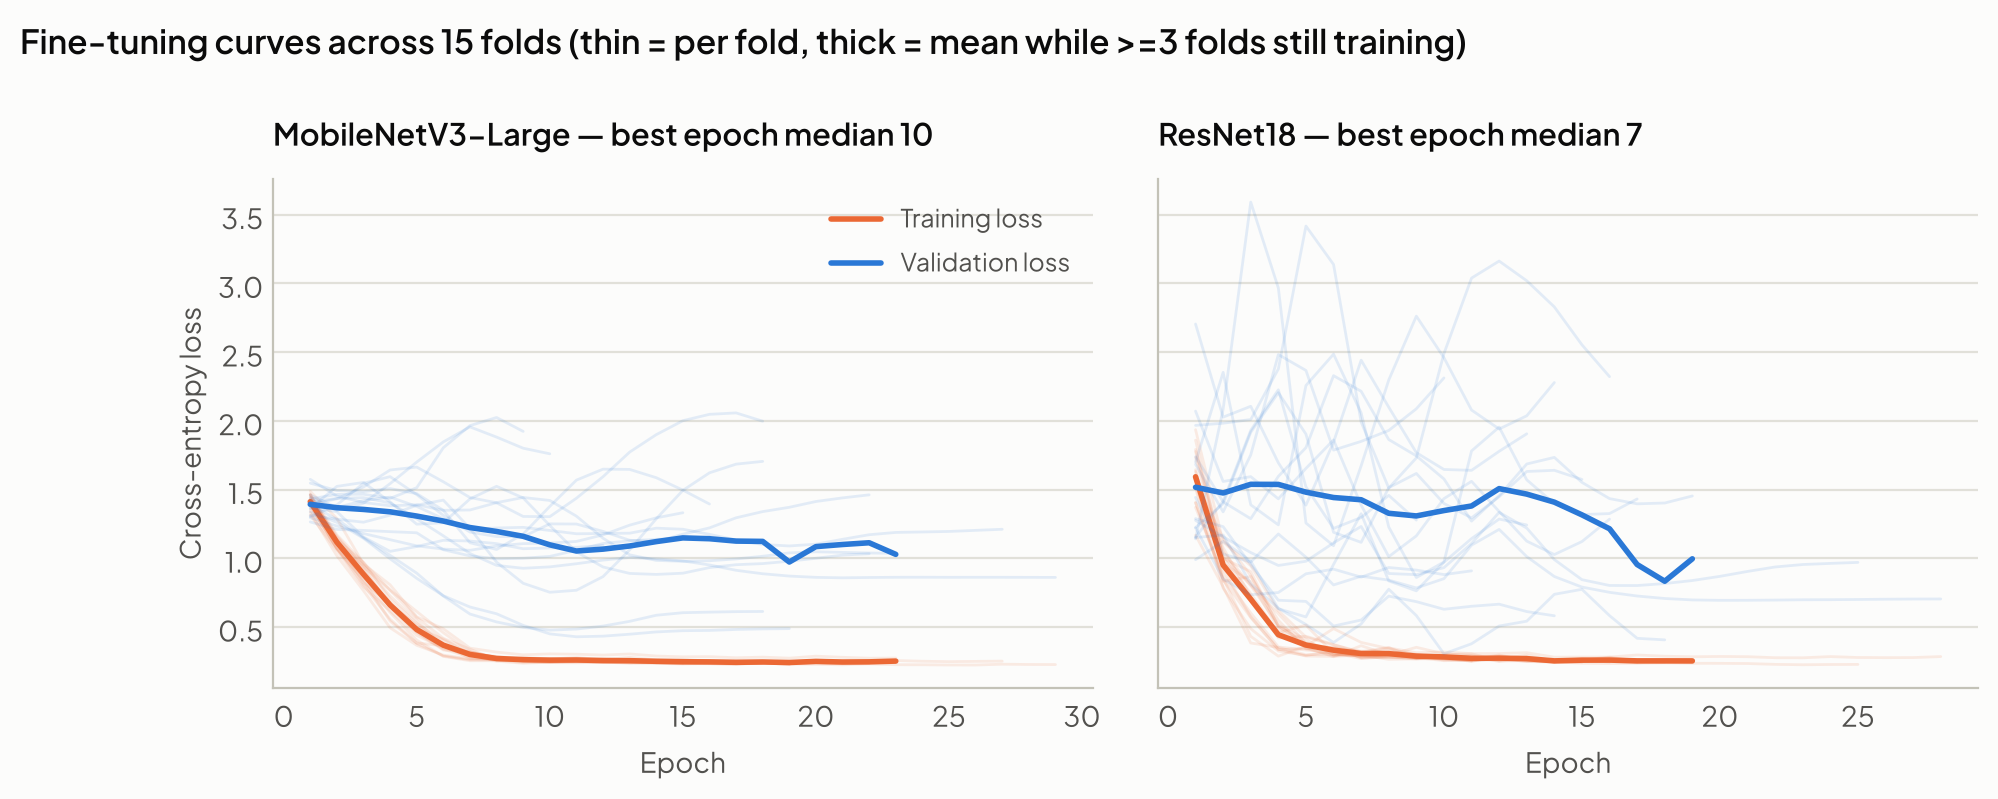

,crop_macro_f1,crop_macro_f1_sd,image_macro_f1,train_seconds_total
model,,,,
cnn_ft_mobilenet_v3_large,0.649,0.075,0.599,228.719
cnn_ft_resnet18,0.579,0.122,0.556,274.828
cnn_probe_mobilenet_v3_large,0.630,0.036,0.660,2.151


In [8]:
display(Image(str(ROOT / "artifacts/figures/training_curves.png"), width=900))
full = pd.read_csv(ROOT / "artifacts/metrics/model_comparison.csv").set_index("model")
full.loc[["cnn_ft_mobilenet_v3_large", "cnn_ft_resnet18", "cnn_probe_mobilenet_v3_large"], ["crop_macro_f1", "crop_macro_f1_sd", "image_macro_f1", "train_seconds_total"]].round(3)

Fine-tuning drives the training loss to ~0.25 while validation loss stays near 1.0: with ~32 training people per fold the
network memorises. It is ~100x slower than the frozen probe and not better on held-out groups, so it is not deployed.

## 5. Final model: train on all data and export (to a temporary folder, checked against the shipped bundle)

In [9]:
import tempfile
from salat_vision.config import load_config
from salat_vision.export import train_and_export
tmp = Path(tempfile.mkdtemp())
cfg_tmp = load_config(overrides={"paths": {"models_dir": str(tmp)}})
out = train_and_export(cfg_tmp, log=print)
new = json.loads((out / "manifest.json").read_text())
shipped = json.loads((ROOT / "models/salat_vision_v1/manifest.json").read_text())
cmp = pd.DataFrame([{"file": f["name"], "re-exported sha256": f["sha256"][:16], "shipped sha256": g["sha256"][:16],
                     "identical": f["sha256"] == g["sha256"]} for f, g in zip(new["files"], shipped["files"])])
cmp

feature cache built in 8.7s — 40 instances, 37 images
pose classifier pose_logreg: {'clf__C': 10.0}


ONNX parity: {'max_abs_diff': 1.7523765563964844e-05, 'min_cosine': 0.9999998807907104, 'n': 40}
bundle written to /tmp/tmpst6w1b7i/salat_vision_v1


,file,re-exported sha256,shipped sha256,identical
0,cnn_embedder_mobilenet_v3_large.onnx,e48a550aabd1ddef,e48a550aabd1ddef,True
1,image_classifier.joblib,1dbb13ae42026159,1dbb13ae42026159,True
2,pose_classifier.joblib,0ec4181b50b3be17,0ec4181b50b3be17,True


The scikit-learn heads are bit-for-bit reproducible. If the ONNX bytes differ, it is only exporter metadata; the
embedding parity check (cosine ≥ 0.9999 against PyTorch on all crops) is enforced inside `train_and_export`.